# Baseline Model: SimplestCNN

In [1]:
import sys
sys.path.append('..')

import torch
import torch.nn as nn
import torch.optim as optim

from src.utils import creating_datasets
from src.model import SimplestCNN
from src.train import train_model, plot_training_history, evaluate_on_test

device = torch.device('cpu')

## Load Data

In [2]:
train_dataset, val_dataset, test_dataset = creating_datasets(
    root_dir='../data/raw',
    test_size=0.2,
    val_size=0.1,
    random_state=42
)

from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Training samples: 1531
Validation samples: 219
Test samples: 438


## Model Architecture

In [3]:
model = SimplestCNN(num_classes=3, dropout_rate=0.3).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)

SimplestCNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(4, 4))
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1024, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=3, bias=True)
  )
)


## Training

In [4]:
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=15,
    device=device
)

Epoch [1/15] Train Loss: 1.0118, Train Acc: 0.4853 | Val Loss: 0.8845, Val Acc: 0.5479
Epoch [2/15] Train Loss: 0.7318, Train Acc: 0.7113 | Val Loss: 0.4431, Val Acc: 0.8539
Epoch [3/15] Train Loss: 0.4232, Train Acc: 0.8641 | Val Loss: 0.3735, Val Acc: 0.8402
Epoch [4/15] Train Loss: 0.2768, Train Acc: 0.9112 | Val Loss: 0.2366, Val Acc: 0.9132
Epoch [5/15] Train Loss: 0.2327, Train Acc: 0.9177 | Val Loss: 0.1622, Val Acc: 0.9406
Epoch [6/15] Train Loss: 0.1784, Train Acc: 0.9432 | Val Loss: 0.1376, Val Acc: 0.9498
Epoch [7/15] Train Loss: 0.1756, Train Acc: 0.9360 | Val Loss: 0.1105, Val Acc: 0.9635
Epoch [8/15] Train Loss: 0.1572, Train Acc: 0.9484 | Val Loss: 0.0702, Val Acc: 0.9863
Epoch [9/15] Train Loss: 0.1352, Train Acc: 0.9523 | Val Loss: 0.0820, Val Acc: 0.9635
Epoch [10/15] Train Loss: 0.1429, Train Acc: 0.9464 | Val Loss: 0.0649, Val Acc: 0.9772
Epoch [11/15] Train Loss: 0.1126, Train Acc: 0.9667 | Val Loss: 0.1052, Val Acc: 0.9589
Epoch [12/15] Train Loss: 0.0998, Train A

## Training Curves

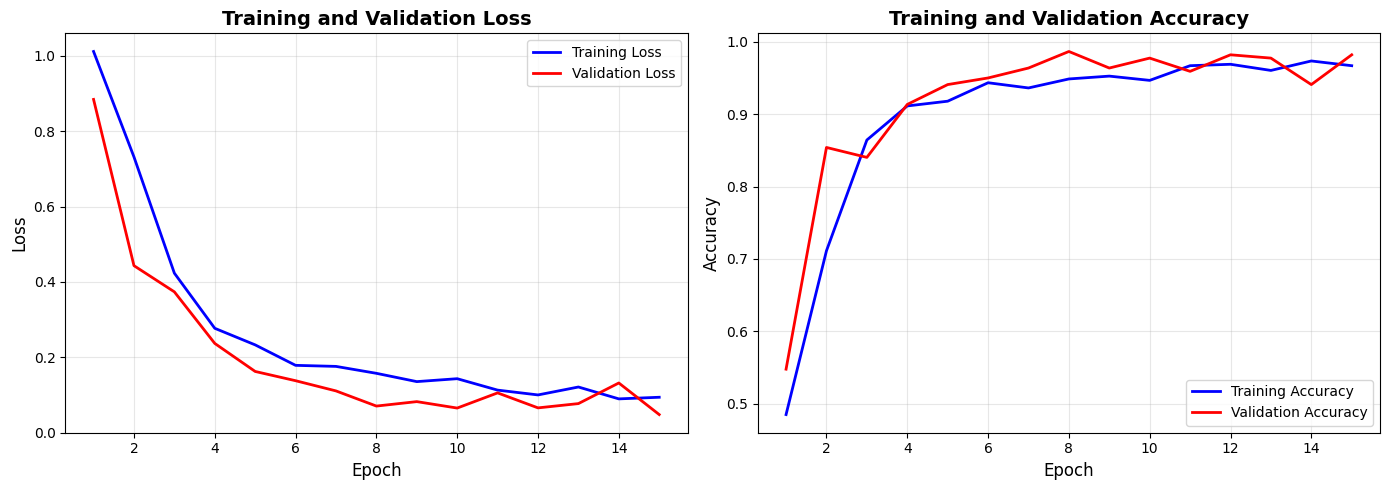

In [5]:
plot_training_history(history, save_path='../reports/figures/baseline_training_curves.png')

## Test Set Evaluation

In [6]:
test_accuracy = evaluate_on_test(model, test_loader, device)
print(f'Baseline Test Accuracy: {test_accuracy:.4f}')

Baseline Test Accuracy: 0.9772


## Save Model

In [7]:
torch.save(model.state_dict(), '../models/baseline_simplest_cnn.pth')